In [1]:
import numpy as np

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

En este notebook se van a comparar los distintos criterios de re-muestreo.

En sistema con el que se va a trabajar es:

- Ecuación estado:

$$
x_t = 0.5 \cdot x_{t-1} + \frac{25\cdot x_{t-1}}{1+x_{t-1}^2}+ w_t,\;\;\; w_t \sim \mathcal{N}(0, Q)
$$

- Ecuación de observación

$$
y_t = x_t + 0.05\cdot x_t^{2} + v_t,\;\;\; v_t \sim \mathcal{N}(0, R)
$$

### 1.Influencia del ruido de transición Q

En este primer apartado se estudia la influencia del ruido de transición y del criterio para realizar el remuestreo. Cuando $Q$ es muy pequeño, el estado evoluciona de forma determinista y, si el resampling es muy frecuente, puede implicar un riesgo de pérdida de diversidad de las partículas.

In [2]:
# Funcion de transicion y observación

def f(x):
    return (
        0.5 * x +
        25*x / (1 + x**2)
    )


def h(x):
    return x + 0.05 * (x ** 2)

In [ ]:
# Definición del modelo de observación (fijo)
R = np.array([[ ]])

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

- Bootstrap Particle Filter

In [ ]:
import pickle

#--------------
# CONFIGURACIÓN
#--------------

# Longitud de la simlación
T = 100

# Estado inicial
x0 = np.array([[0.0]])

# Valores de la matriz de covarianza de la transición
Q = [1e-3, 1e-1, 1.0, 5.0, 10.0]

# Numero de simulaciones
n_simulations = 5

# Numero ejecuciones
n_runs = 5

#--------------
# RESULTADOS
#--------------
results_bpf_always = []
results_bpf_adaptive = []
results_bpf_never = []


for q in Q:

    # Definicion modelo de transicion
    noise_transition = GaussianNoise(q)
    transition = AdditiveTransitionModel(f, noise_transition)

    # Lista de simulaciones para Q
    q_results_bpf_always = []
    q_results_bpf_adaptive = []
    q_results_bpf_never = []

    #---------------------------------------------
    # 'n_simulations' SIMULACIONES INDEPENDIENTES
    #---------------------------------------------

    for simulation in range(n_simulations):

        # Simulacion
        x_true, y_obs = system_simulation(transition, observation, x0, T)

        # Lista para 'n_runs' filtrados
        simulation_bpf_always = []
        simulation_bpf_adaptive = []
        simulation_bpf_never = []

        #------------------------------
        # 'n_runs' EJECUCIONES FILTRO
        #------------------------------

        for run in range(n_runs):

            # Iniciacion Bootstarp Particle Filter
            bpf = BootstrapParticleFilter(N=1000, transition_model=transition, observation_model=observation)

            # Re-muestreo siempre
            bpf.initialize(mean=np.array([0.0]), cov = np.eye(1))
            est_bpf_always = bpf.run_filter(y_obs, resample_threshold=(bpf.N))

            est_bpf_always["run"] = run
            simulation_bpf_always.append(est_bpf_always)

            # Re-muestreo adaptativo
            bpf.reset(mean=np.array([0.0]), cov = np.eye(1))
            est_bpf_adaptive = bpf.run_filter(y_obs, resample_threshold=bpf.N/2)

            est_bpf_adaptive["run"] = run
            simulation_bpf_adaptive.append(est_bpf_adaptive)

            # Re-muestreo nunca
            bpf.reset(mean=np.array([0.0]), cov = np.eye(1))
            est_bpf_never = bpf.run_filter(y_obs)

            est_bpf_never["run"] = run
            simulation_bpf_never.append(est_bpf_never)


        #---------------------
        # GUARDAR SIMULACION
        #---------------------

        simulation_result_bpf_always = {
            "Q": q,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_bpf_always
        }

        simulation_result_bpf_adaptive = {
            "Q": q,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_bpf_adaptive
        }

        simulation_result_bpf_never = {
            "Q": q,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_bpf_never
        }

        q_results_bpf_always.append(simulation_result_bpf_always)
        q_results_bpf_adaptive.append(simulation_result_bpf_adaptive)
        q_results_bpf_never.append(simulation_result_bpf_never)

    #-------------------------------
    # GUARDAR RESULTADOS DE ESTE Q
    #-------------------------------
    
    results_bpf_always.append(q_results_bpf_always)
    results_bpf_adaptive.append(q_results_bpf_adaptive)
    results_bpf_never.append(q_results_bpf_never)

    print(f"Matriz {q} finalizado")        

#-------------------------------
# GUARDAR RESULTADOS DE ESTE Q
#-------------------------------

with open("results_bpf_always2.pkl", "wb") as file:
    pickle.dump(results_bpf_always, file)

with open("results_bpf_adaptive2.pkl", "wb") as file:
    pickle.dump(results_bpf_adaptive, file)

with open("results_bpf_never2.pkl", "wb") as file:
    pickle.dump(results_bpf_never, file)


In [1]:
# Importar resultados
import pickle

with open('results_bpf_always2.pkl', 'rb') as file:
    results_bpf_always = pickle.load(file)

with open('results_bpf_adaptive2.pkl', 'rb') as file:
    results_bpf_adaptive = pickle.load(file)

with open("results_bpf_never2.pkl", "rb") as file:
    results_bpf_never = pickle.load(file)

In [2]:
from functions1 import calculate_rmse, calculate_rmse_in_time, calculate_loglikelihood, ESS_per_time, unique_particles, plot_ESS, plot_comparisons, plot_particles_diversity

In [3]:
from particle_filter.plots.plot_comparisons import plot_comparisons

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Matriz de covarianza Q', ylabel='RMSE'>)

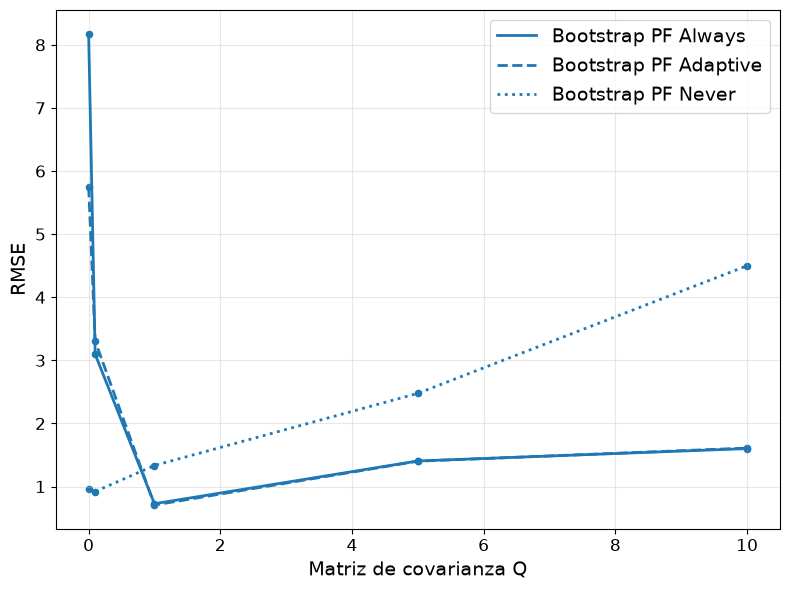

In [4]:
import numpy as np

Q = [1e-3, 1e-1, 1.0, 5.0, 10.0]

rmse_bpf_always, rmse_bpf_always_sim = calculate_rmse(results_bpf_always)
rmse_bpf_adaptive, rmse_bpf_adaptive_sim = calculate_rmse(results_bpf_adaptive)
rmse_bpf_never, rmse_bpf_never_sim = calculate_rmse(results_bpf_never)

# Media de 'n_simulations' para cada q
res_rmse_bpf_always = [ np.mean(rmse_bpf_always_sim[q]) for q in Q]
res_rmse_bpf_adaptive = [ np.mean(rmse_bpf_adaptive_sim[q]) for q in Q]
res_rmse_bpf_never = [ np.mean(rmse_bpf_never_sim[q]) for q in Q]

# STD para cada q
std_rmse_bpf_always = [np.std(rmse_bpf_always_sim[q], ddof=1) for q in Q]
std_rmse_bpf_adaptive = [np.std(rmse_bpf_adaptive_sim[q], ddof=1) for q in Q]
std_rmse_bpf_never = [np.std(rmse_bpf_never_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF Always": { "Matriz de covarianza Q": Q, "RMSE": res_rmse_bpf_always, "RMSE_errorbars": std_rmse_bpf_always }, 
        "Bootstrap PF Adaptive": { "Matriz de covarianza Q": Q, "RMSE": res_rmse_bpf_adaptive, "RMSE_errorbars": std_rmse_bpf_adaptive },
        "Bootstrap PF Never": { "Matriz de covarianza Q": Q, "RMSE": res_rmse_bpf_never, "RMSE_errorbars": std_rmse_bpf_never }, 
    }, "Matriz de covarianza Q", "RMSE","Comparación del RMSE según la matriz de covarianza Q", False
)

In [5]:
import numpy as np

Q = [1e-3, 1e-1, 1.0, 5.0, 10.0]

rmse_t_bpf_always, rmse_acumulado_bpf_always = calculate_rmse_in_time(results_bpf_always, 5, 5, 100, Q)
rmse_t_bpf_adaptive, rmse_acumulado_bpf_adaptive = calculate_rmse_in_time(results_bpf_adaptive, 5, 5, 100, Q)
rmse_t_bpf_never, rmse_acumulado_bpf_never = calculate_rmse_in_time(results_bpf_never, 5, 5, 100, Q)

0.001


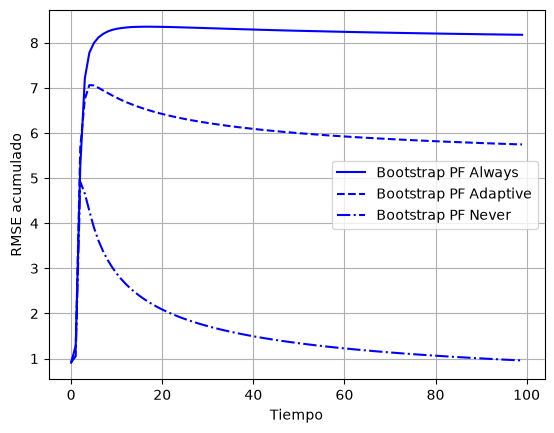

0.1


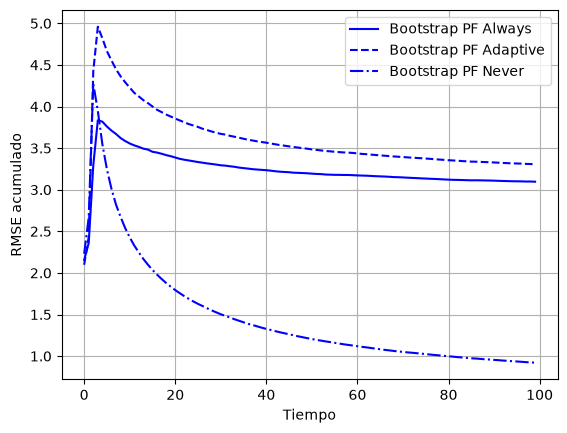

1.0


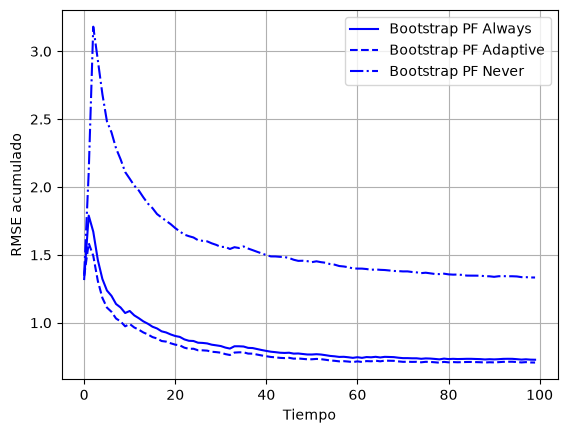

5.0


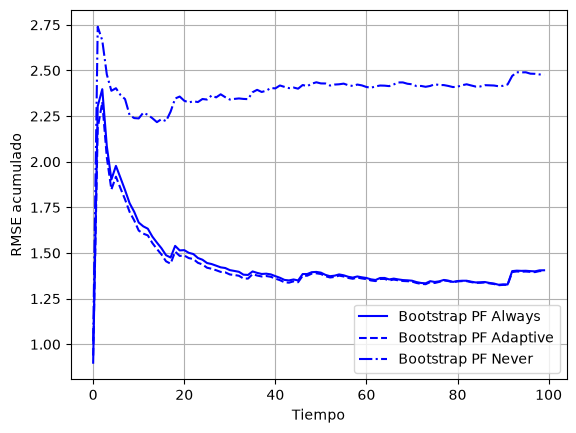

10.0


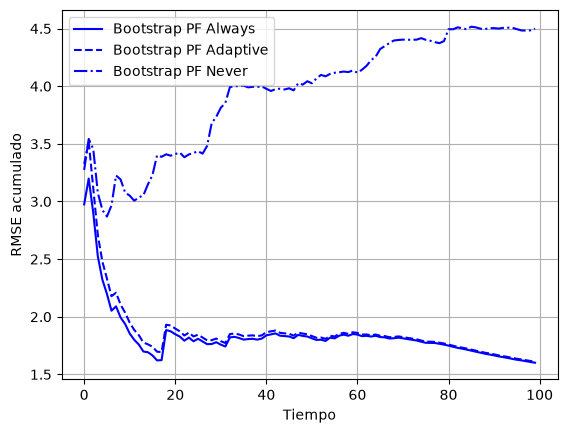

In [8]:
import matplotlib.pyplot as plt

T = 100

for q in Q:

    print(q)

    plt.plot(np.arange(T), rmse_acumulado_bpf_always[q], color = "blue", linestyle = "-", label="Bootstrap PF Always")
    plt.plot(np.arange(T), rmse_acumulado_bpf_adaptive[q], color = "blue", linestyle = "--", label="Bootstrap PF Adaptive")
    plt.plot(np.arange(T), rmse_acumulado_bpf_never[q], color = "blue", linestyle = "-.", label="Bootstrap PF Never")

    plt.xlabel("Tiempo")
    plt.ylabel("RMSE acumulado")
    #plt.title(f"RMSE acumulado en función del criterio de remuestreo (Q={q})")

    plt.grid(True)
    plt.legend()
    plt.show()

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Matriz de covarianza Q', ylabel='Logverosimilitud'>)

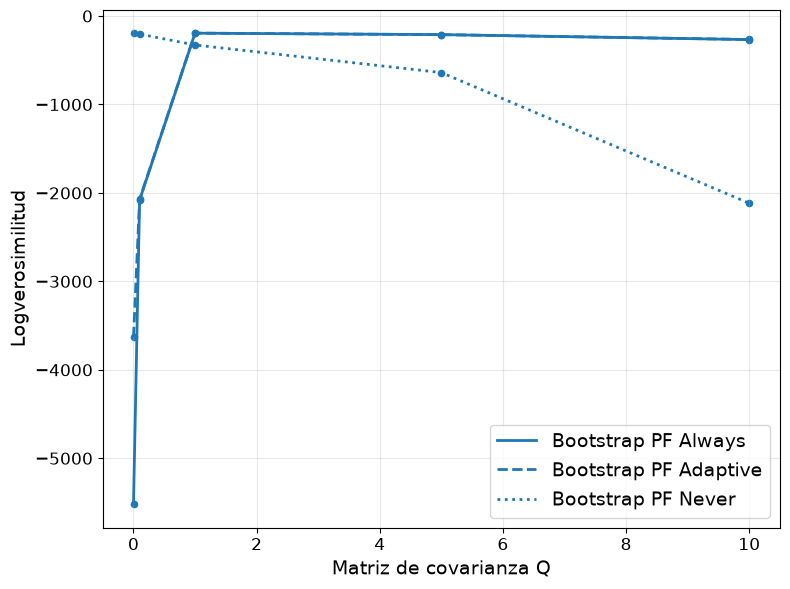

In [6]:
Q = [1e-3, 1e-1, 1.0, 5.0, 10.0]

loglikelihood_bpf_always, loglikelihood_bpf_always_sim = calculate_loglikelihood(results_bpf_always)
loglikelihood_bpf_adaptive, loglikelihood_bpf_adaptive_sim = calculate_loglikelihood(results_bpf_adaptive)
loglikelihood_bpf_never, loglikelihood_bpf_never_sim = calculate_loglikelihood(results_bpf_never)

# Media de 'n_simulations' para cada q
res_loglikelihood_bpf_always = [ np.mean(loglikelihood_bpf_always_sim[q]) for q in Q]
res_loglikelihood_bpf_adaptive = [ np.mean(loglikelihood_bpf_adaptive_sim[q]) for q in Q]
res_loglikelihood_bpf_never = [ np.mean(loglikelihood_bpf_never_sim[q]) for q in Q]

# STD para cada q
std_loglikelihood_bpf_always = [np.std(loglikelihood_bpf_always_sim[q], ddof=1) for q in Q]
std_loglikelihood_bpf_adaptive = [np.std(loglikelihood_bpf_adaptive_sim[q], ddof=1) for q in Q]
std_loglikelihood_bpf_never = [np.std(loglikelihood_bpf_never_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF Always": { "Matriz de covarianza Q": Q, "Logverosimilitud": res_loglikelihood_bpf_always, "log_likelihood_errorbars": std_rmse_bpf_always }, 
        "Bootstrap PF Adaptive": { "Matriz de covarianza Q": Q, "Logverosimilitud": res_loglikelihood_bpf_adaptive, "log_likelihood_errorbars": std_rmse_bpf_adaptive },
        "Bootstrap PF Never": { "Matriz de covarianza Q": Q, "Logverosimilitud": res_loglikelihood_bpf_never, "log_likelihood_errorbars": std_rmse_bpf_never }, 
    }, "Matriz de covarianza Q", "Logverosimilitud","Comparación de la logverosimilitud según la matriz de covarianza Q", False
)

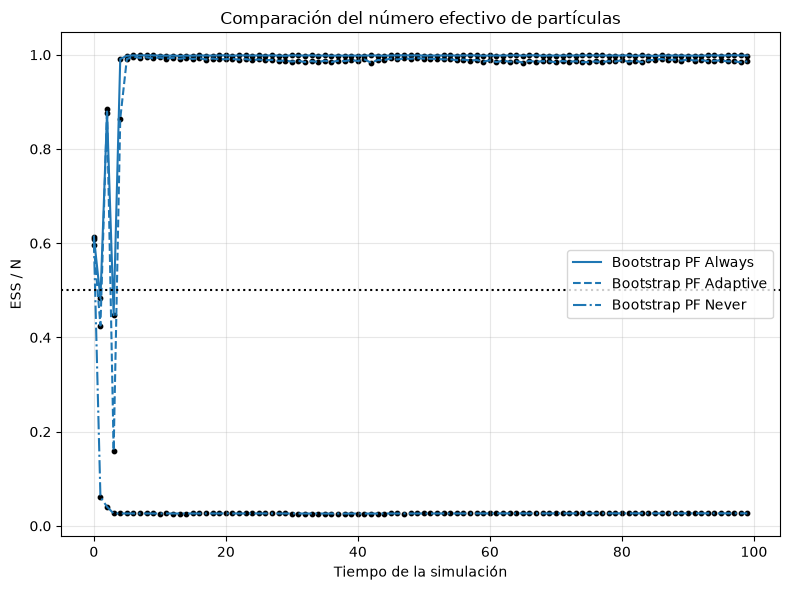

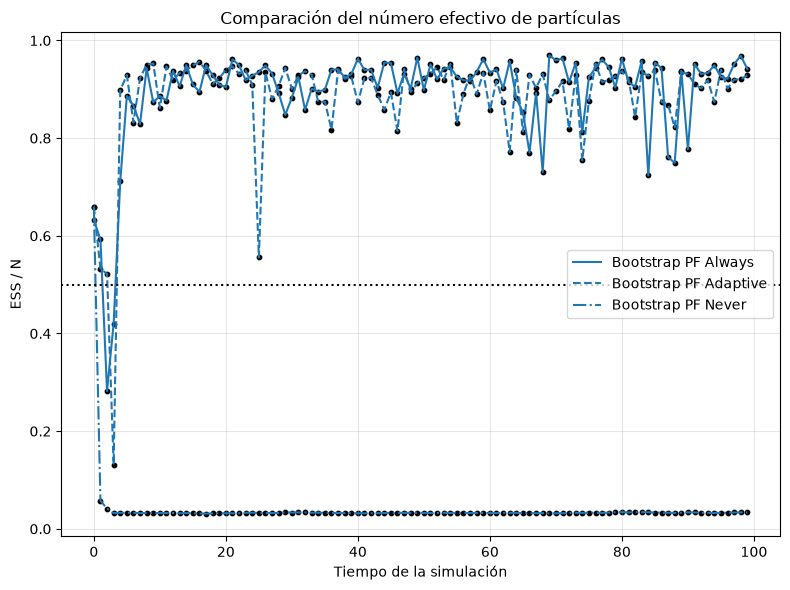

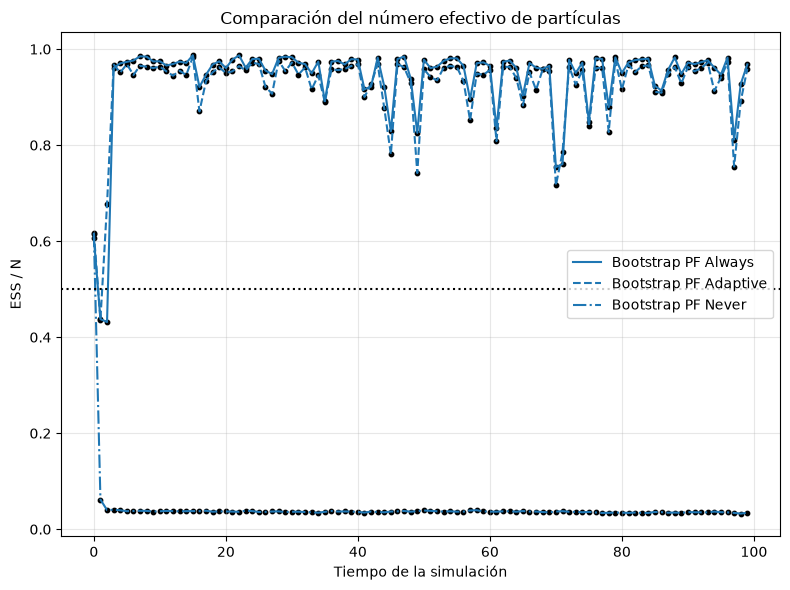

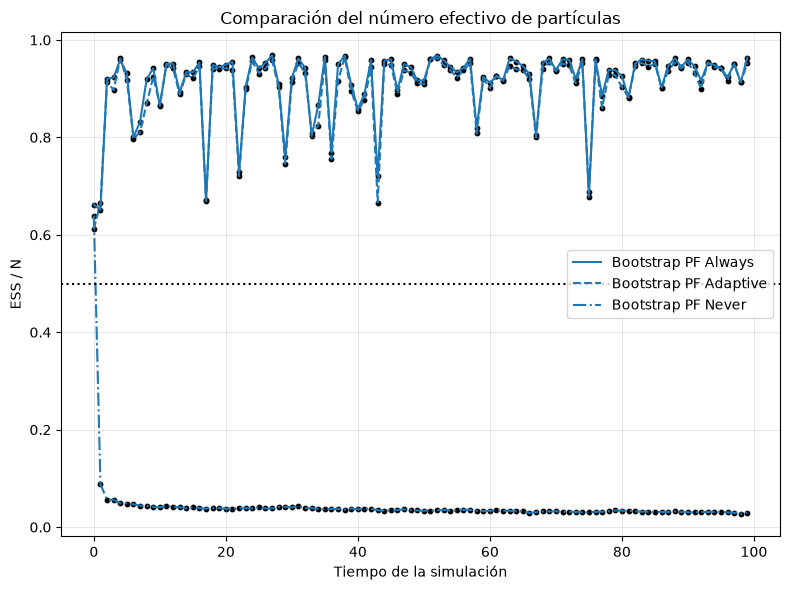

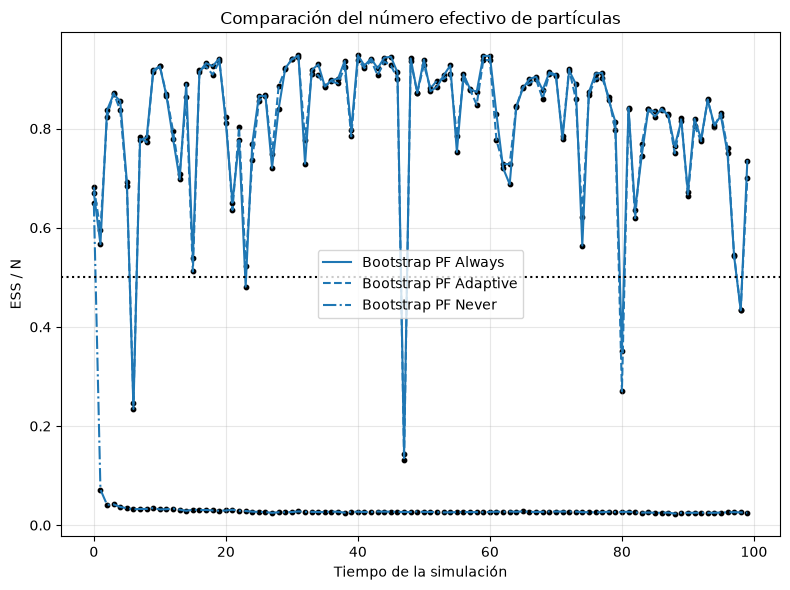

In [10]:
ESS_bpf_always = ESS_per_time(results_bpf_always)
ESS_bpf_adaptive = ESS_per_time(results_bpf_adaptive)
ESS_bpf_never = ESS_per_time(results_bpf_never)

for q in Q:

    plot_ESS( {
        "Bootstrap PF Always": ESS_bpf_always[q],
        "Bootstrap PF Adaptive": ESS_bpf_adaptive[q],
        "Bootstrap PF Never": ESS_bpf_never[q]
        },
        resampling_threshold=0.5    
    )

In [11]:
n_unique_bpf_always = unique_particles(results_bpf_always)
n_unique_bpf_adaptive = unique_particles(results_bpf_adaptive)
n_unique_bpf_never = unique_particles(results_bpf_never)


0.001


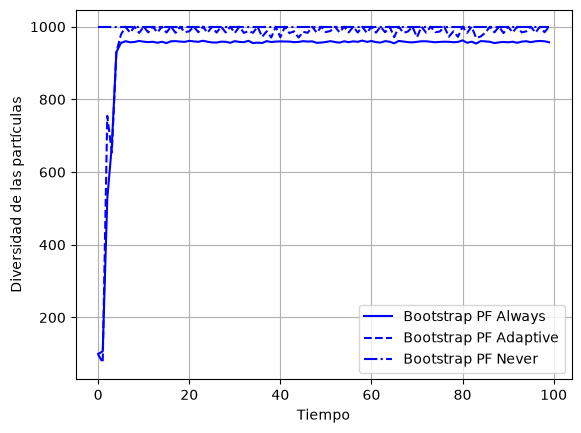

0.1


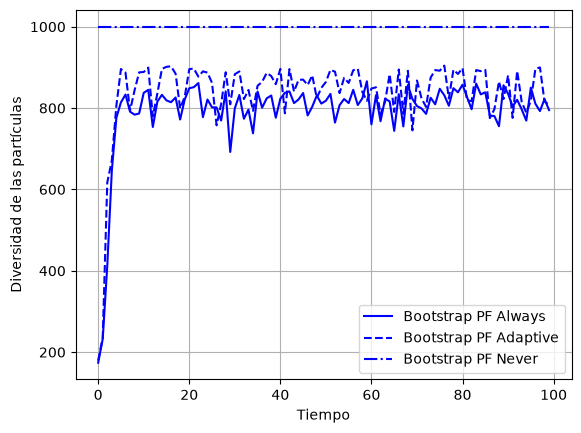

1.0


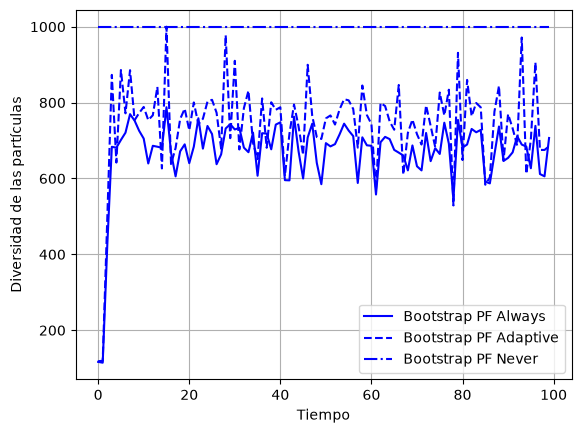

5.0


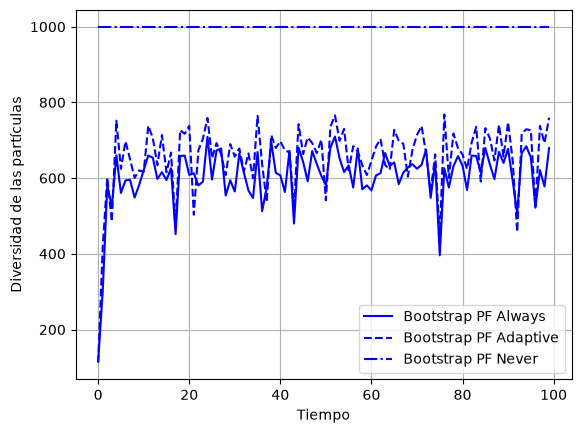

10.0


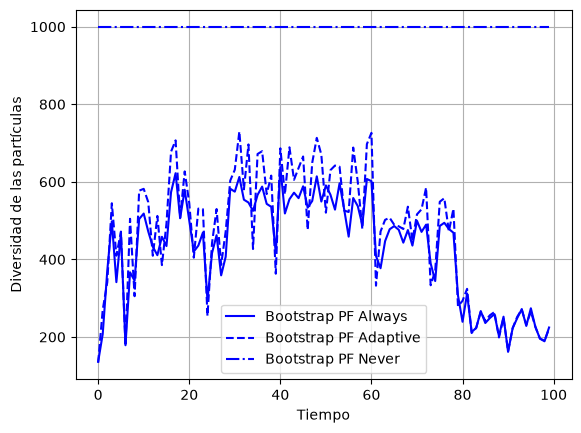

In [12]:
for q in Q:

    print(q)

    plt.plot(np.arange(T), n_unique_bpf_always[q], color="blue", linestyle="-", label="Bootstrap PF Always")
    plt.plot(np.arange(T), n_unique_bpf_adaptive[q], color="blue", linestyle="--", label="Bootstrap PF Adaptive")
    plt.plot(np.arange(T), n_unique_bpf_never[q], color="blue", linestyle="-.", label="Bootstrap PF Never")

    plt.xlabel("Tiempo")
    plt.ylabel("Diversidad de las partículas")
    #plt.title(f"Comparación de la diversidad de las partículas (Q={q})")

    plt.grid(True)

    plt.legend()
    plt.show()

Con $Q$ muy pequeño, el sistema es suficientemente determinista y predecible y no es necesario corregir la degeneración mediante remuestreo con mucha frecuencia. Para estos escenarios, si no se remuestrea, se tiene una alta diversidad de partículas (porque no se remuestrea) pero una alta degeneración en los pesos de las partículas. Por tanto, el estado es descrito por un pequeño grupo de partículas (probablemente una sola) que dado que el sistema es muy determinista describe el estado mejor que los filtrados que remuestrean. 

Al aumentar el ruido de transición, el remuestreo deja de ser contraproducente y empieza a ser útil. La transición empieza a ser más ruidosa, por lo que el paso del remuestreo puede eliminar partículas poco compatibles con la observación y concentra el esfuerzo en las zonas relevantes.

En escenarios con baja incertidumbre de transición, el remuestreo frecuente puede introducir una pérdida innecesaria de diversidad, mientras que, al aumentar la incertidumbre de transición, la degeneración de pesos adquiere mayor relevancia y las estrategias de remuestreo proporcionana una ventaja.

- Auxiliary Particle Filter

In [14]:
import pickle

#--------------
# CONFIGURACIÓN
#--------------

# Longitud de la simlación
T = 100

# Estado inicial
x0 = np.array([[0.0]])

# Valores de la matriz de covarianza de la transición
Q = [1e-3, 1e-1, 1.0, 5.0, 10.0]

# Numero de simulaciones
n_simulations = 5

# Numero ejecuciones
n_runs = 5

#--------------
# RESULTADOS
#--------------
results_apf_always = []
results_apf_adaptive = []
results_apf_never = []


for q in Q:

    # Definicion modelo de transicion
    noise_transition = GaussianNoise(q)
    transition = AdditiveTransitionModel(f, noise_transition)

    # Lista de simulaciones para Q
    q_results_apf_always = []
    q_results_apf_adaptive = []
    q_results_apf_never = []

    #---------------------------------------------
    # 'n_simulations' SIMULACIONES INDEPENDIENTES
    #---------------------------------------------

    for simulation in range(n_simulations):

        # Simulacion
        x_true, y_obs = system_simulation(transition, observation, x0, T)

        # Lista para 'n_runs' filtrados
        simulation_apf_always = []
        simulation_apf_adaptive = []
        simulation_apf_never = []

        #------------------------------
        # 'n_runs' EJECUCIONES FILTRO
        #------------------------------

        for run in range(n_runs):

            # Iniciacion Auxiliary Particle Filter
            apf = AuxiliaryParticleFilter(N=1000, transition_model=transition, observation_model=observation)

            # Re-muestreo siempre
            apf.initialize(mean=np.array([0.0]), cov = np.eye(1))
            est_apf_always = apf.run_filter(y_obs, resample_threshold=(apf.N))

            est_apf_always["run"] = run
            simulation_apf_always.append(est_apf_always)

            # Re-muestreo adaptativo
            apf.reset(mean=np.array([0.0]), cov = np.eye(1))
            est_apf_adaptive = apf.run_filter(y_obs, resample_threshold=apf.N/2)

            est_apf_adaptive["run"] = run
            simulation_apf_adaptive.append(est_apf_adaptive)

            # Re-muestreo nunca
            apf.reset(mean=np.array([0.0]), cov = np.eye(1))
            est_apf_never = apf.run_filter(y_obs)

            est_apf_never["run"] = run
            simulation_apf_never.append(est_apf_never)


        #---------------------
        # GUARDAR SIMULACION
        #---------------------

        simulation_result_apf_always = {
            "Q": q,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_apf_always
        }

        simulation_result_apf_adaptive = {
            "Q": q,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_apf_adaptive
        }

        simulation_result_apf_never = {
            "Q": q,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_apf_never
        }

        q_results_apf_always.append(simulation_result_apf_always)
        q_results_apf_adaptive.append(simulation_result_apf_adaptive)
        q_results_apf_never.append(simulation_result_apf_never)

    #-------------------------------
    # GUARDAR RESULTADOS DE ESTE Q
    #-------------------------------
    
    results_apf_always.append(q_results_apf_always)
    results_apf_adaptive.append(q_results_apf_adaptive)
    results_apf_never.append(q_results_apf_never)

    print(f"Matriz {q} finalizado")        

#-------------------------------
# GUARDAR RESULTADOS DE ESTE Q
#-------------------------------

with open("results_apf_always2.pkl", "wb") as file:
    pickle.dump(results_apf_always, file)

with open("results_apf_adaptive2.pkl", "wb") as file:
    pickle.dump(results_apf_adaptive, file)

with open("results_apf_never2.pkl", "wb") as file:
    pickle.dump(results_apf_never, file)

Matriz 0.001 finalizado
Matriz 0.1 finalizado
Matriz 1.0 finalizado
Matriz 5.0 finalizado
Matriz 10.0 finalizado


In [13]:
# Importar resultados
import pickle

with open('results_apf_always2.pkl', 'rb') as file:
    results_apf_always = pickle.load(file)

with open('results_apf_adaptive2.pkl', 'rb') as file:
    results_apf_adaptive = pickle.load(file)

with open('results_apf_never2.pkl', 'rb') as file:
    results_apf_never = pickle.load(file)

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Matriz de covarianza Q', ylabel='RMSE'>)

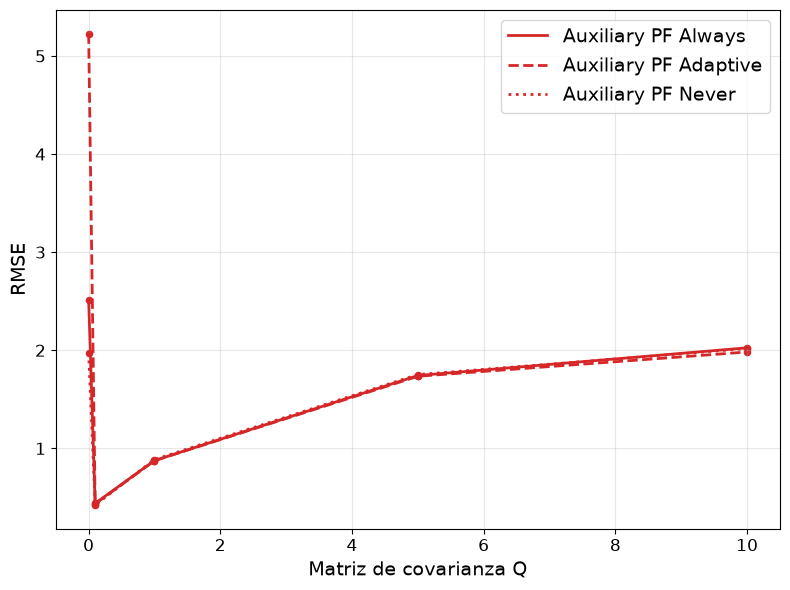

In [14]:
import numpy as np

Q = [1e-3, 1e-1, 1.0, 5.0, 10.0]

rmse_apf_always, rmse_apf_always_sim = calculate_rmse(results_apf_always)
rmse_apf_adaptive, rmse_apf_adaptive_sim = calculate_rmse(results_apf_adaptive)
rmse_apf_never, rmse_apf_never_sim = calculate_rmse(results_apf_never)

# Media de 'n_simulations' para cada q
res_rmse_apf_always = [ np.mean(rmse_apf_always_sim[q]) for q in Q]
res_rmse_apf_adaptive = [ np.mean(rmse_apf_adaptive_sim[q]) for q in Q]
res_rmse_apf_never = [ np.mean(rmse_apf_never_sim[q]) for q in Q]

# STD para cada q
std_rmse_apf_always = [np.std(rmse_apf_always_sim[q], ddof=1) for q in Q]
std_rmse_apf_adaptive = [np.std(rmse_apf_adaptive_sim[q], ddof=1) for q in Q]
std_rmse_apf_never = [np.std(rmse_apf_never_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Auxiliary PF Always": { "Matriz de covarianza Q": Q, "RMSE": res_rmse_apf_always, "RMSE_errorbars": std_rmse_apf_always }, 
        "Auxiliary PF Adaptive": { "Matriz de covarianza Q": Q, "RMSE": res_rmse_apf_adaptive, "RMSE_errorbars": std_rmse_apf_adaptive },
        "Auxiliary PF Never": { "Matriz de covarianza Q": Q, "RMSE": res_rmse_apf_never, "RMSE_errorbars": std_rmse_apf_never }, 
    }, "Matriz de covarianza Q", "RMSE", "Comparación del RMSE según la matriz de covarianza Q"
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Matriz de covarianza Q', ylabel='Logverosimilitud'>)

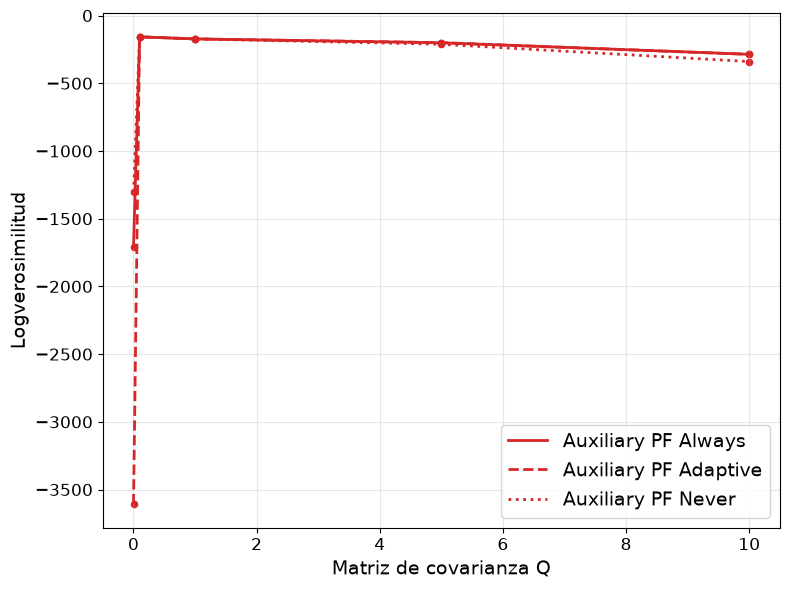

In [15]:
Q = [1e-3, 1e-1, 1.0,5.0, 10.0]

loglikelihood_apf_always, loglikelihood_apf_always_sim = calculate_loglikelihood(results_apf_always)
loglikelihood_apf_adaptive, loglikelihood_apf_adaptive_sim = calculate_loglikelihood(results_apf_adaptive)
loglikelihood_apf_never, loglikelihood_apf_never_sim = calculate_loglikelihood(results_apf_never)

# Media de 'n_simulations' para cada q
res_loglikelihood_apf_always = [ np.mean(loglikelihood_apf_always_sim[q]) for q in Q]
res_loglikelihood_apf_adaptive = [ np.mean(loglikelihood_apf_adaptive_sim[q]) for q in Q]
res_loglikelihood_apf_never = [ np.mean(loglikelihood_apf_never_sim[q]) for q in Q]

# STD para cada q
std_loglikelihood_apf_always = [np.std(loglikelihood_apf_always_sim[q], ddof=1) for q in Q]
std_loglikelihood_apf_adaptive = [np.std(loglikelihood_apf_adaptive_sim[q], ddof=1) for q in Q]
std_loglikelihood_apf_never = [np.std(loglikelihood_apf_never_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Auxiliary PF Always": { "Matriz de covarianza Q": Q, "Logverosimilitud": res_loglikelihood_apf_always, "log_likelihood_errorbars": std_rmse_apf_always }, 
        "Auxiliary PF Adaptive": { "Matriz de covarianza Q": Q, "Logverosimilitud": res_loglikelihood_apf_adaptive, "log_likelihood_errorbars": std_rmse_apf_adaptive },
        "Auxiliary PF Never": { "Matriz de covarianza Q": Q, "Logverosimilitud": res_loglikelihood_apf_never, "log_likelihood_errorbars": std_rmse_apf_never }, 
    }, "Matriz de covarianza Q", "Logverosimilitud", "Comparación de la logverosimilitud según la matriz de covarianza Q"
)

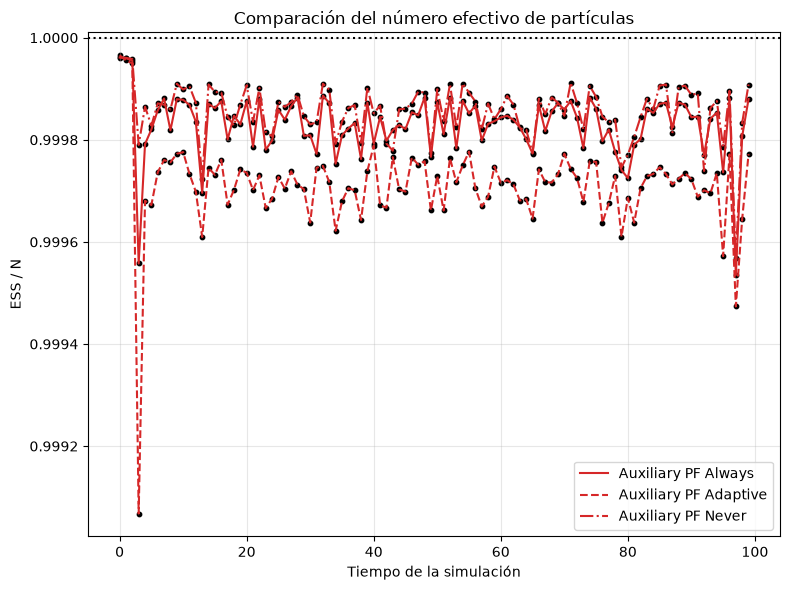

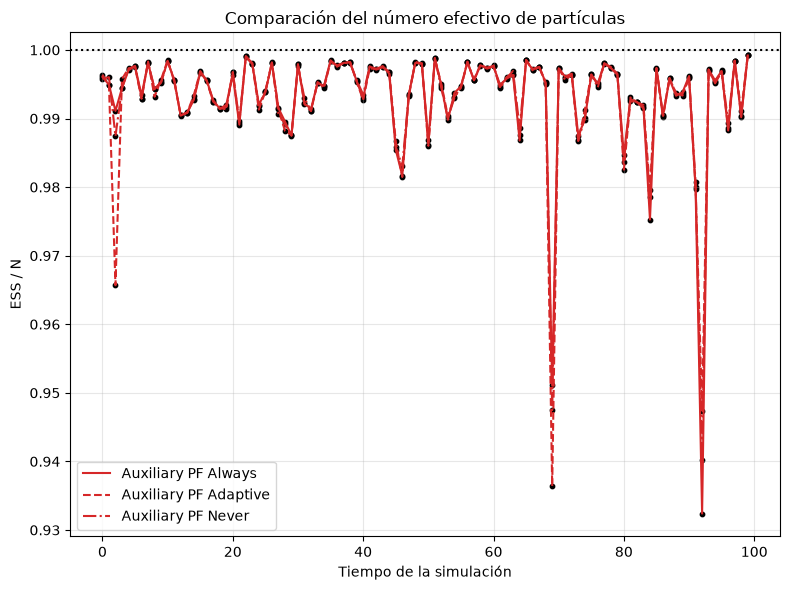

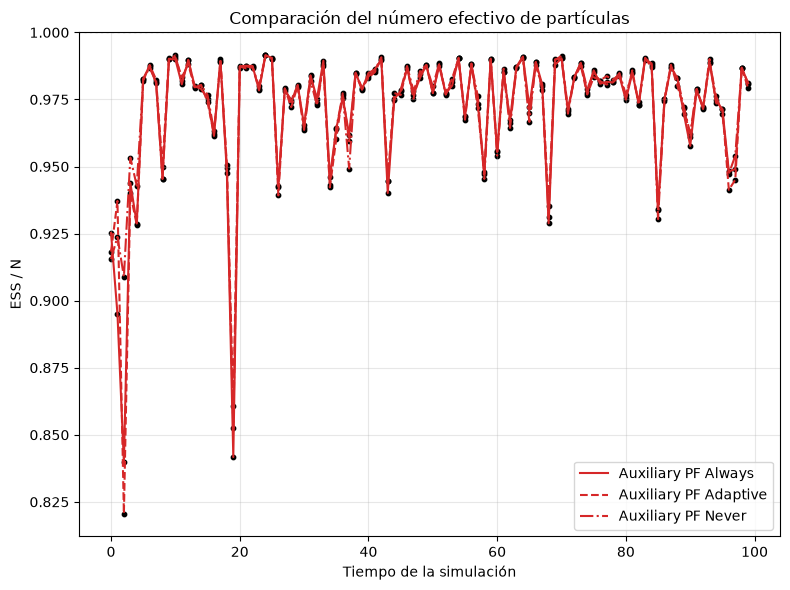

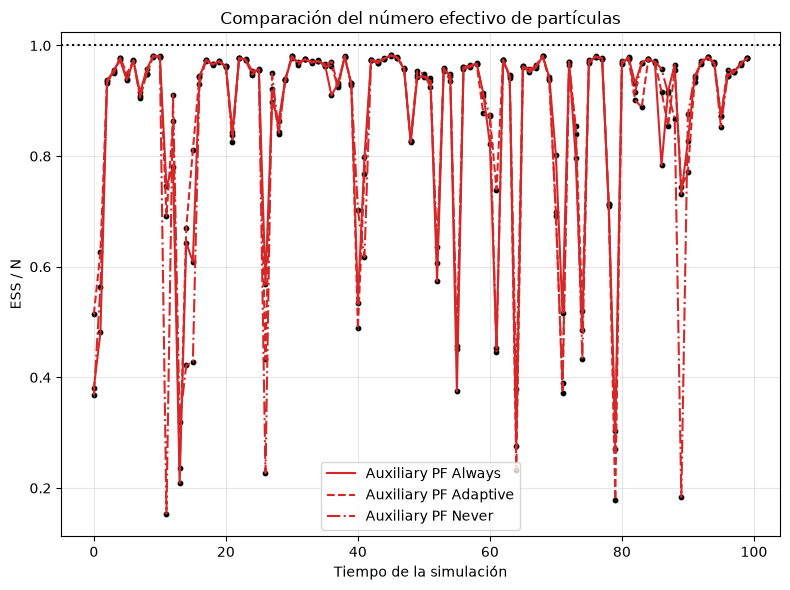

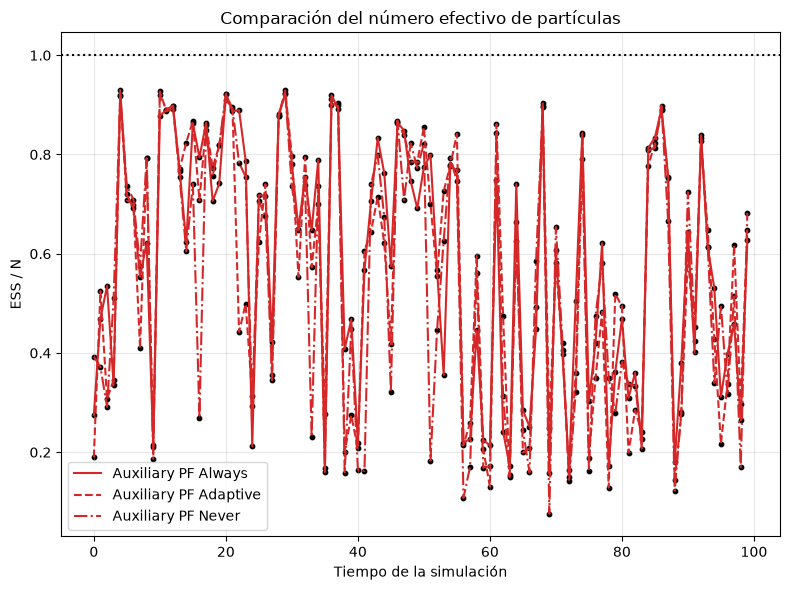

In [6]:
ESS_apf_always = ESS_per_time(results_apf_always)
ESS_apf_adaptive = ESS_per_time(results_apf_adaptive)
ESS_apf_never = ESS_per_time(results_apf_never)

for q in Q:
    plot_ESS( {
        "Auxiliary PF Always": ESS_apf_always[q],
        "Auxiliary PF Adaptive": ESS_apf_adaptive[q],
        "Auxiliary PF Never": ESS_apf_never[q]
        },
        resampling_threshold=1.0      
    )

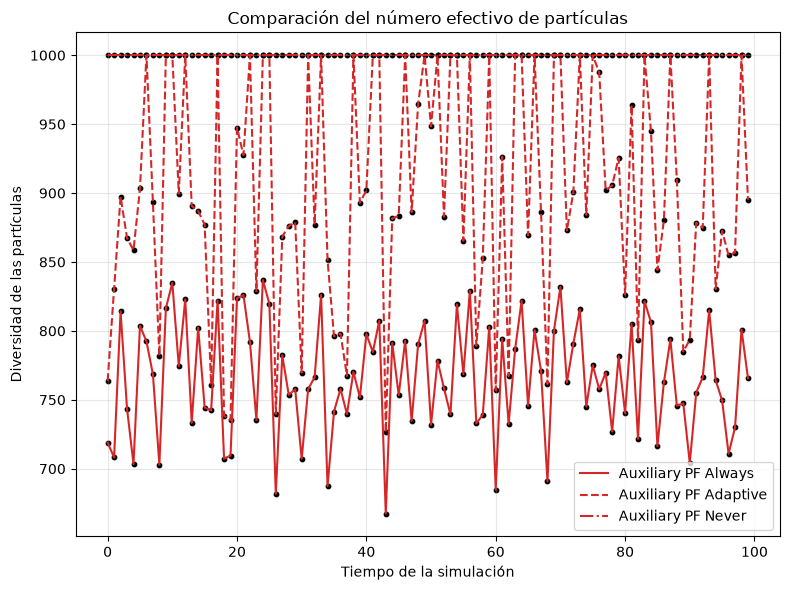

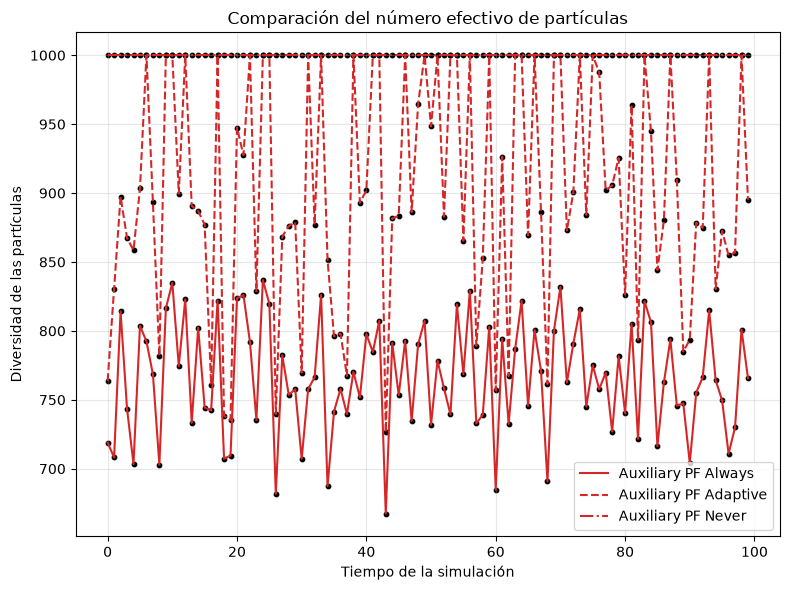

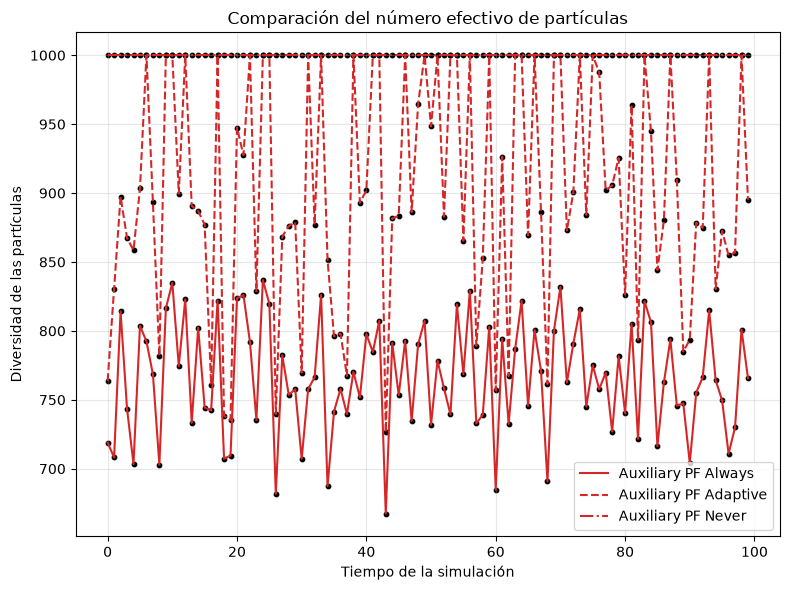

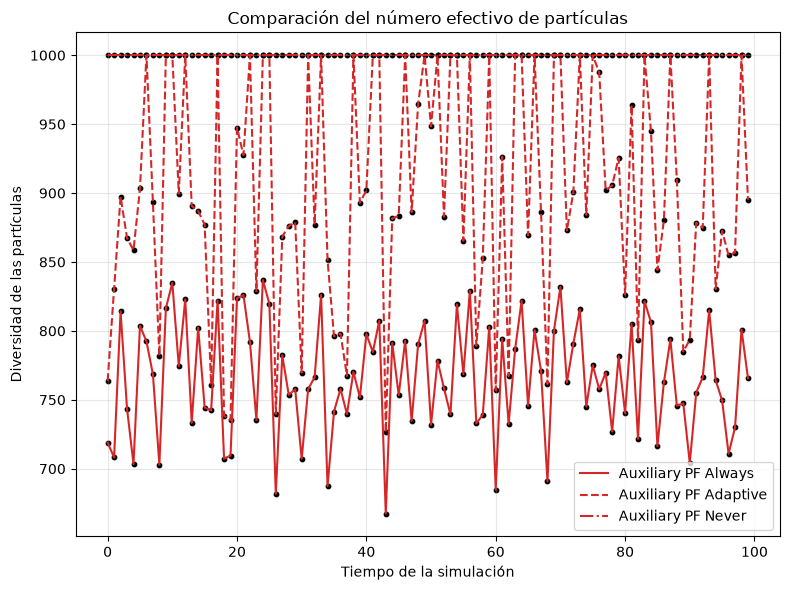

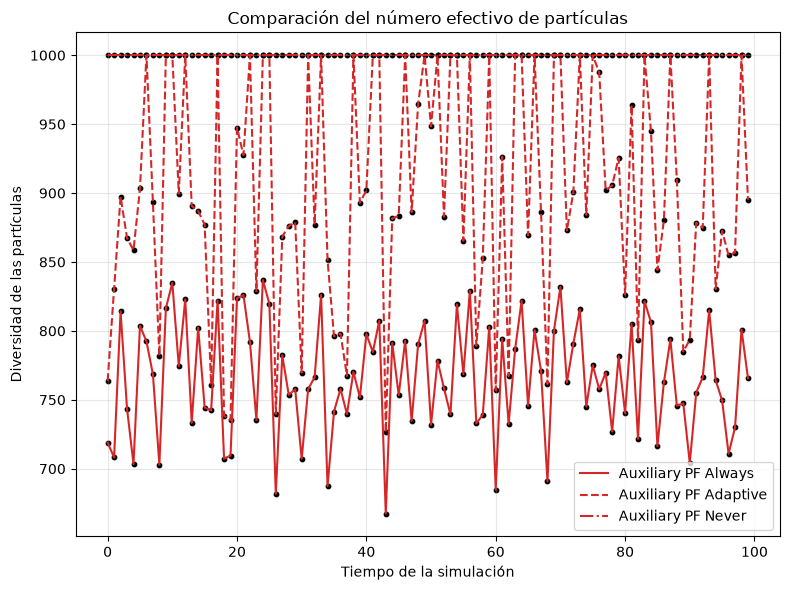

In [7]:
n_unique_apf_always = unique_particles(results_apf_always)
n_unique_apf_adaptive = unique_particles(results_apf_adaptive)
n_unique_apf_never = unique_particles(results_apf_never)

for q in Q:
    plot_particles_diversity( {
        "Auxiliary PF Always": n_unique_apf_always[1.0],
        "Auxiliary PF Adaptive": n_unique_apf_adaptive[1.0],
        "Auxiliary PF Never": n_unique_apf_never[1.0]
        }  
    )

Para el APF, si bien se tiene una clara desventaja para el remuestreo Adaptativo para el menor valor del ruido de transición, inmediatamente se igualan los rendimientos para los distintos criterios de remuestreo. Esto se debe principalmente al hecho de que en este filtrado ya se realiza en sí un tipo de remuestreo al elegir en el paso de actualización aquellas partículas que explican mejor la observación recibida. Este paso provoca que los rendimientos obtenidos para los algoritmos con los tres criterios de remuestreo se igualen.

### 2. Umbral de remuestreo adaptativo

En este segundo apartado se va a comparar el rendimiento según el umbral de remuestreo. Fijando $Q$ y $R$, el remuestreo se realizará según el número de muestras efectivas: $10\%,30\%, 50\%, 70\%$ y $90\%$.

In [2]:
# Funcion de transicion y observación

def f(x):
    return (
        0.5 * x +
        25*x / (1 + x**2)
    )


def h(x):
    return x + 0.05 * (x ** 2)

In [3]:
# Definición del modelo de transición
Q = np.array([[1.]])

noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

# Definición del modelo de observación 
R = np.array([[1.]])

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

In [5]:
import pickle
import numpy as np

# ----------------
# CONFIGURACIÓN
# ----------------

T = 100

x0 = np.array([[0.0]])

alphas = [0.1, 0.3, 0.5, 0.7, 0.9]

n_simulations = 5
n_runs = 5

# ----------------
# GENERAR SIMULACIONES
# ----------------
# Generamos una vez las simulaciones y las reutilizamos
# para TODOS los alpha.

simulations = []

for simulation in range(n_simulations):

    x_true, y_obs = system_simulation(
        transition,
        observation,
        x0,
        T
    )

    simulations.append({
        "simulation": simulation,
        "x_true": x_true,
        "y_obs": y_obs
    })


# ----------------
# RESULTADOS
# ----------------

results_bpf = []
results_apf = []


# Recorremos alpha
for alpha in alphas:

    alpha_results_bpf = []
    alpha_results_apf = []

    # ---------------------------------------------
    # USAR LAS MISMAS SIMULACIONES PARA ESTE ALPHA
    # ---------------------------------------------

    for sim_data in simulations:

        simulation = sim_data["simulation"]
        x_true = sim_data["x_true"]
        y_obs = sim_data["y_obs"]

        simulation_bpf = []
        simulation_apf = []

        # ------------------------------
        # n_runs EJECUCIONES DEL FILTRO
        # ------------------------------

        for run in range(n_runs):

            # Bootstrap Particle Filter
            bpf = BootstrapParticleFilter(
                N=1000,
                transition_model=transition,
                observation_model=observation
            )

            bpf.initialize(
                mean=np.array([0.0]),
                cov=np.eye(1)
            )

            est_bpf = bpf.run_filter(
                y_obs,
                resample_threshold=alpha * bpf.N
            )

            est_bpf["run"] = run
            simulation_bpf.append(est_bpf)


            # Auxiliary Particle Filter
            apf = AuxiliaryParticleFilter(
                N=1000,
                transition_model=transition,
                observation_model=observation
            )

            apf.initialize(
                mean=np.array([0.0]),
                cov=np.eye(1)
            )

            est_apf = apf.run_filter(
                y_obs,
                resample_threshold=alpha * apf.N
            )

            est_apf["run"] = run
            simulation_apf.append(est_apf)


        # ---------------------
        # GUARDAR SIMULACIÓN
        # ---------------------

        simulation_result_bpf = {
            "alpha": alpha,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_bpf
        }

        simulation_result_apf = {
            "alpha": alpha,
            "simulation": simulation,
            "x_true": x_true,
            "y_obs": y_obs,
            "runs": simulation_apf
        }

        alpha_results_bpf.append(simulation_result_bpf)
        alpha_results_apf.append(simulation_result_apf)


    # -------------------------------
    # GUARDAR RESULTADOS DE ESTE ALPHA
    # -------------------------------

    results_bpf.append(alpha_results_bpf)
    results_apf.append(alpha_results_apf)

    print(f"Umbral {alpha} finalizado")


# -------------------------------
# GUARDAR RESULTADOS
# -------------------------------

with open('results_bpf_exp2_3.pkl', 'wb') as file:
    pickle.dump(results_bpf, file)

with open('results_apf_exp2_3.pkl', 'wb') as file:
    pickle.dump(results_apf, file)

Umbral 0.1 finalizado
Umbral 0.3 finalizado
Umbral 0.5 finalizado
Umbral 0.7 finalizado
Umbral 0.9 finalizado


In [8]:
# Importar resultados
import pickle

with open('results_bpf_exp2.pkl', 'rb') as file:
    results_bpf = pickle.load(file)

with open('results_apf_exp2.pkl', 'rb') as file:
    results_apf = pickle.load(file)

In [6]:
from functions2 import calculate_rmse, calculate_loglikelihood, ESS_per_time, unique_particles, plot_comparisons, plot_ESS, plot_particles_diversity

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (RMSE)'}, xlabel='alpha', ylabel='RMSE'>)

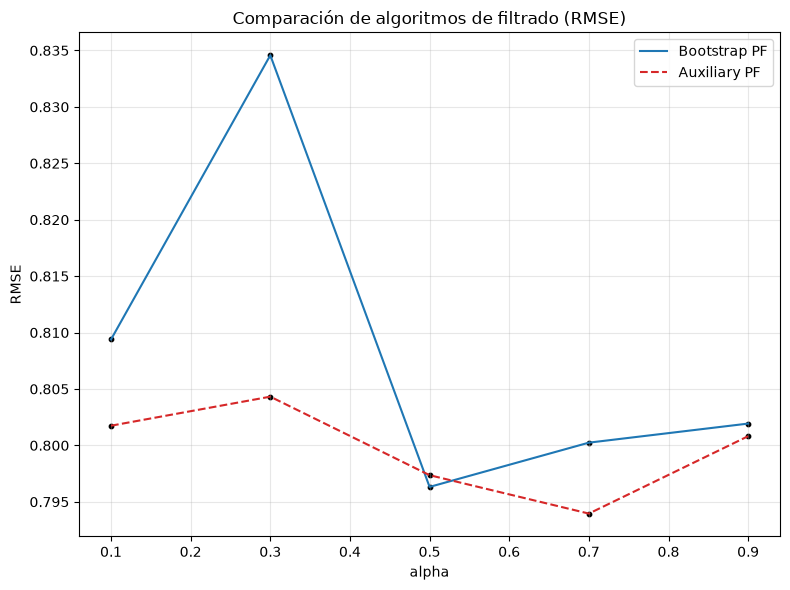

In [9]:
import numpy as np

alphas = [0.1, 0.3, 0.5, 0.7, 0.9]

rmse_bpf, rmse_bpf_sim = calculate_rmse(results_bpf)
rmse_apf, rmse_apf_sim = calculate_rmse(results_apf)

# Media de 'n_simulations' para cada alpha
res_rmse_bpf = [ np.mean(rmse_bpf_sim[alpha]) for alpha in alphas]
res_rmse_apf = [ np.mean(rmse_apf_sim[alpha]) for alpha in alphas]

# STD para cada q
std_rmse_bpf = [np.std(rmse_bpf_sim[alpha], ddof=1) for alpha in alphas]
std_rmse_apf = [np.std(rmse_apf_sim[alpha], ddof=1) for alpha in alphas]

plot_comparisons(
    {
        "Bootstrap PF": { "alpha": alphas, "RMSE": res_rmse_bpf, "RMSE_errorbars": std_rmse_bpf }, 
        "Auxiliary PF": { "alpha": alphas, "RMSE": res_rmse_apf, "RMSE_errorbars": std_rmse_apf },
    }, "alpha", "RMSE", False
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de algoritmos de filtrado (Log-verosimilitud)'}, xlabel='alpha', ylabel='Log-verosimilitud'>)

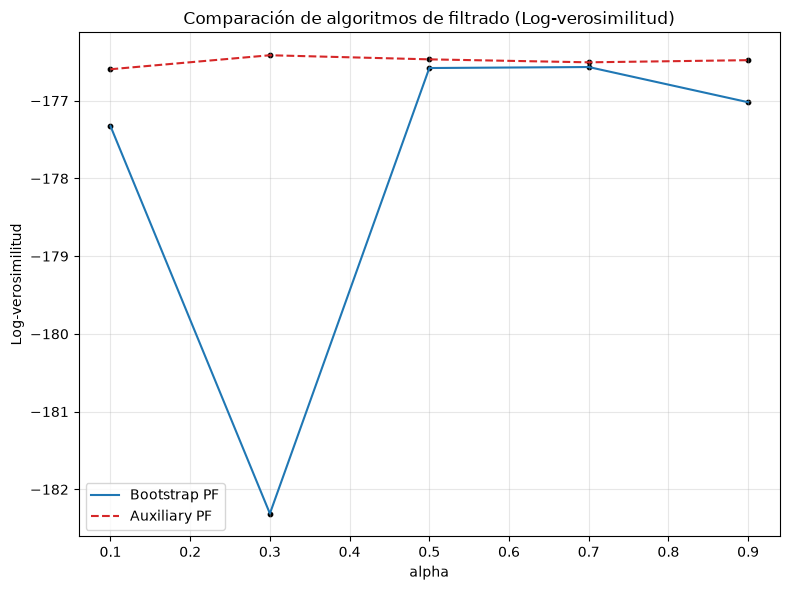

In [11]:
import numpy as np

alphas = [0.1, 0.3, 0.5, 0.7, 0.9]

loglikelihood_bpf, loglikelihood_bpf_sim = calculate_loglikelihood(results_bpf)
loglikelihood_apf, loglikelihood_apf_sim = calculate_loglikelihood(results_apf)

# Media de 'n_simulations' para cada alpha
res_loglikelihood_bpf = [ np.mean(loglikelihood_bpf_sim[alpha]) for alpha in alphas]
res_loglikelihood_apf = [ np.mean(loglikelihood_apf_sim[alpha]) for alpha in alphas]

# STD para cada q
std_loglikelihood_bpf = [np.std(loglikelihood_bpf_sim[alpha], ddof=1) for alpha in alphas]
std_loglikelihood_apf = [np.std(loglikelihood_apf_sim[alpha], ddof=1) for alpha in alphas]

plot_comparisons(
    {
        "Bootstrap PF": { "alpha": alphas, "Log-verosimilitud": res_loglikelihood_bpf, "Log-verosimilitud_errorbars": std_loglikelihood_bpf }, 
        "Auxiliary PF": { "alpha": alphas, "Log-verosimilitud": res_loglikelihood_apf, "Log-verosimilitud_errorbars": std_loglikelihood_apf },
    }, "alpha", "Log-verosimilitud", False
)

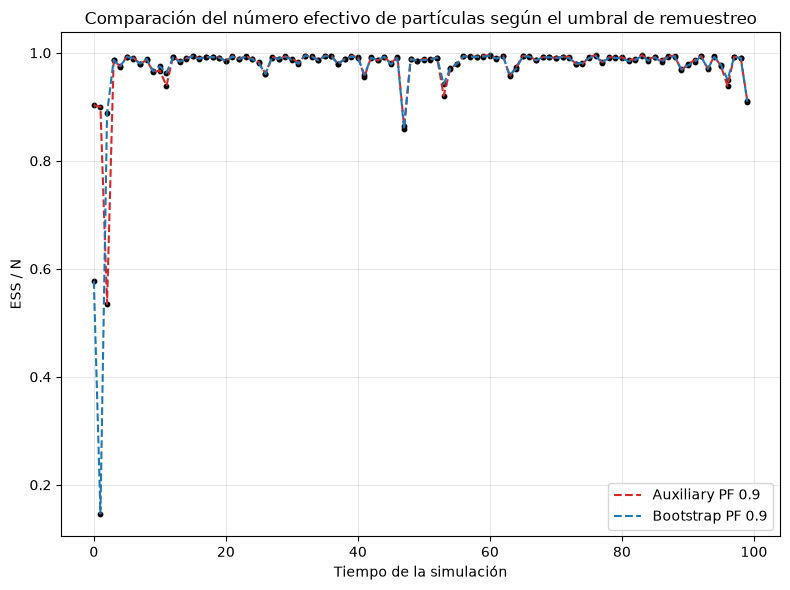

In [22]:
ESS_bpf = ESS_per_time(results_bpf)
ESS_apf = ESS_per_time(results_apf)

plot_ESS( {
    ("Auxiliary PF", 0.9): ESS_apf[0.9],
    ("Bootstrap PF", 0.9): ESS_bpf[0.9]
    }
)

In [ ]:
n_unique_bpf = unique_particles(results_bpf)
n_unique_apf = unique_particles(results_apf)

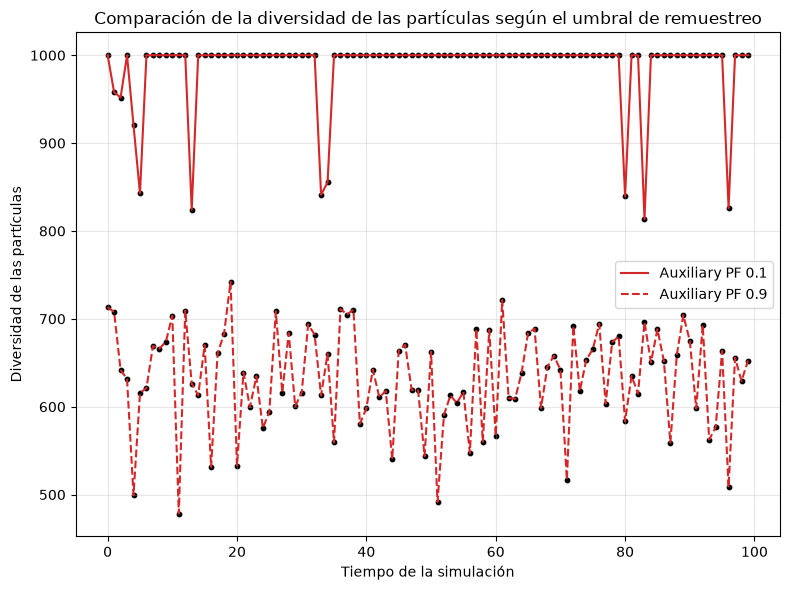

In [16]:
plot_particles_diversity( {
    ("Auxiliary PF", 0.1): n_unique_apf[0.1],
    ("Auxiliary PF", 0.9): n_unique_apf[0.9]
    }
)